# Section 3 — Internal Pressure: Shopee แบกอะไรอยู่
**Business Question:** Shopee มีทรัพยากรพอจะรบทุก Frontline หรือไม่?

### ข้อมูลที่ใช้ (Verified Public Data)
- **งบการเงิน บจก. ช้อปปี้ (ประเทศไทย) จาก DBD (ปี 2023–2025 / พ.ศ. 2566–2568):**
  - ปี 2023 (2566): รายได้ 29,476 ลบ. | กำไรสุทธิ 2,165 ลบ.
  - ปี 2024 (2567): รายได้ 49,964 ลบ. | กำไรสุทธิ 4,630 ลบ. (+113.9% YoY)
  - ปี 2025 (2568): รายได้ 88,387 ลบ. | กำไรสุทธิ **2,756 ลบ. (-40.5% YoY)**
- **โครงสร้างต้นทุนผู้ขาย & มาตรการลด GP กระทรวงพาณิชย์:**
  - ผู้ขายรายย่อยแบกต้นทุนรวม ~34.7% ของยอดขาย
  - กระทรวงพาณิชย์เจรจาปรับลดเพดาน GP ของ Shopee จาก **19.26%** เหลือ **8.03% – 13.91%**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import chart_style

chart_style.setup_plot_style()
COLORS = chart_style.COLORS

trend_df = pd.read_csv("../data/processed/sec03_shopee_financial_trend.csv")
seller_df = pd.read_csv("../data/processed/sec03_seller_cost_burden.csv")
gp_df = pd.read_csv("../data/processed/sec03_gp_reduction.csv")
display(trend_df)
display(seller_df)
display(gp_df)

,year,year_num,revenue_mb,net_profit_mb,revenue_yoy_pct,profit_yoy_pct,net_margin_pct
0,2023 (2566),2023,29476,2165,35.8,-9.0,7.34
1,2024 (2567),2024,49964,4630,69.5,113.9,9.27
2,2025 (2568),2025,88387,2756,76.9,-40.5,3.12


,seller_tier,commission_pct,ads_pct,logistics_pct,promo_fee_pct,payment_fee_pct,total_cost_pct,seller_net_margin_pct
0,ผู้ขายรายเล็ก (Micro/Small SME),12.5,8.5,6.0,4.5,3.21,34.71,8.0
1,ผู้ขายรายกลาง (Mid-tier SME),10.7,6.5,4.8,3.8,3.21,29.01,13.5
2,ผู้ขายรายใหญ่ (Large / Mall),8.5,4.5,3.5,2.5,3.21,22.21,20.0


,period,max_gp_pct,mid_gp_pct,min_gp_pct,note
0,ก่อนลด GP (ปกติ),19.26,13.91,8.03,เพดานสูงสุดหมวดแฟชั่น/ทั่วไป 19.26%
1,หลังลด GP (มาตรการรัฐ),13.91,10.70,8.03,ลดเพดานลงเหลือ 8.03% - 13.91% (ลดสูงสุด -33.3%)


### กราฟ 3.1 — Revenue vs Profit Trend (2023–2025)
- **สื่ออะไร:** รายได้ของ Shopee ประเทศไทยเติบโตก้าวกระโดดแตะ 88,387 ล้านบาทในปี 2025 แต่กำไรสุทธิกลับหดตัวลงถึง **-40.5%** (จาก 4,630 ลบ. เหลือ 2,756 ลบ.) สะท้อนถึงต้นทุนการเผาเงินอุดหนุนคูปองและ Live เพื่อต้านทานการรุกของ TikTok Shop

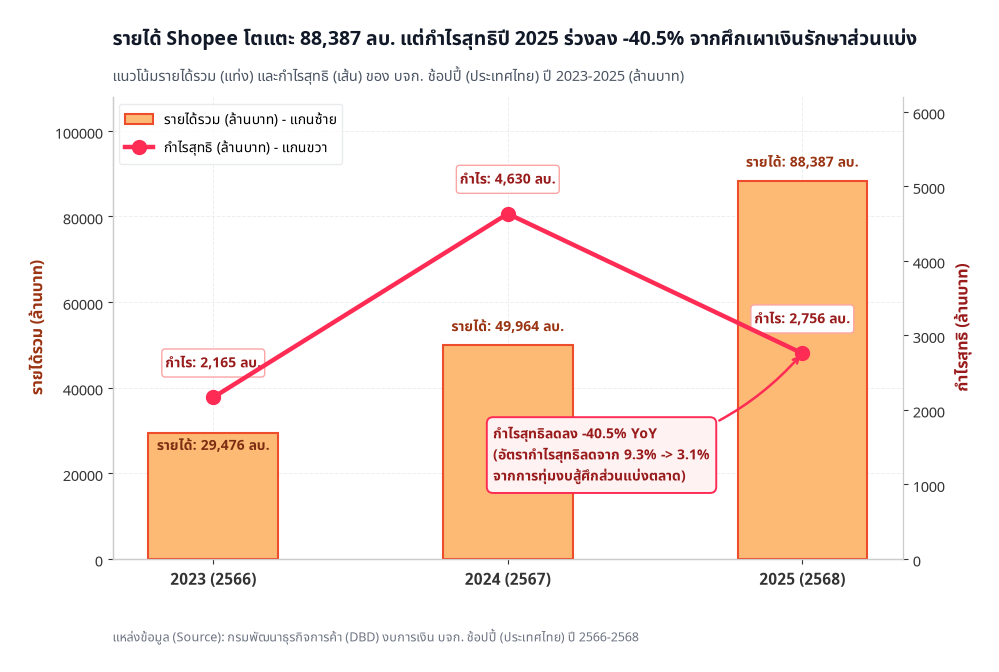

In [2]:
fig, ax1 = plt.subplots(figsize=(10.2, 6.0))

x = np.arange(len(trend_df))
years = trend_df["year"].tolist()
revs = trend_df["revenue_mb"].tolist()
profits = trend_df["net_profit_mb"].tolist()

# Left axis: Revenue bars
bars = ax1.bar(x, revs, width=0.44, color="#FDBA74", edgecolor=COLORS["Shopee"], linewidth=1.5,
               label="รายได้รวม (ล้านบาท) - แกนซ้าย", zorder=3)
for i, b in enumerate(bars):
    h = b.get_height()
    y_pos = h + 1800 if i != 0 else h - 5500
    txt_col = "#9A3412" if i != 0 else "#7C2D12"
    ax1.text(b.get_x() + b.get_width()/2, y_pos, f"รายได้: {h:,.0f} ลบ.",
             ha="center", va="bottom", fontsize=10, fontweight="bold", color=txt_col)

ax1.set_xticks(x)
ax1.set_xticklabels(years, fontsize=11, fontweight="bold")
ax1.set_ylabel("รายได้รวม (ล้านบาท)", fontweight="bold", color="#9A3412")
ax1.set_ylim(0, 108000)

# Right axis: Net Profit line
ax2 = ax1.twinx()
ax2.grid(False)
ax2.spines["top"].set_visible(False)

line = ax2.plot(x, profits, color=COLORS["TikTok Red"], marker="o", markersize=10, linewidth=3.2,
                label="กำไรสุทธิ (ล้านบาท) - แกนขวา", zorder=5)

for i, p in enumerate(profits):
    offset = 320
    ax2.text(x[i], p + offset, f"กำไร: {p:,.0f} ลบ.",
             ha="center", va="bottom", fontsize=10, fontweight="bold", color="#991B1B",
             bbox=dict(boxstyle="round,pad=0.25", facecolor="#FFFFFF", edgecolor="#FCA5A5"))

# Annotate -40.5% drop between 2024 and 2025
ax2.annotate(
    "กำไรสุทธิลดลง -40.5% YoY\n(อัตรากำไรสุทธิลดจาก 9.3% -> 3.1%\nจากการทุ่มงบสู้ศึกส่วนแบ่งตลาด)",
    xy=(2, 2756), xytext=(0.95, 1050),
    fontsize=10, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#FEF2F2", edgecolor=COLORS["TikTok Red"], lw=1.4),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2", color=COLORS["TikTok Red"], lw=1.8),
    zorder=6
)

ax2.set_ylabel("กำไรสุทธิ (ล้านบาท)", fontweight="bold", color="#991B1B")
ax2.set_ylim(0, 6200)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

chart_style.add_title_and_source(
    ax1,
    title="รายได้ Shopee โตแตะ 88,387 ลบ. แต่กำไรสุทธิปี 2025 ร่วงลง -40.5% จากศึกเผาเงินรักษาส่วนแบ่ง",
    subtitle="แนวโน้มรายได้รวม (แท่ง) และกำไรสุทธิ (เส้น) ของ บจก. ช้อปปี้ (ประเทศไทย) ปี 2023-2025 (ล้านบาท)",
    source_text="กรมพัฒนาธุรกิจการค้า (DBD) งบการเงิน บจก. ช้อปปี้ (ประเทศไทย) ปี 2566-2568"
)

plt.savefig("../charts/03_1_revenue_vs_profit_trend.png")
plt.show()

### กราฟ 3.2 — Seller Cost Burden Breakdown
- **สื่ออะไร:** ผู้ขายรายเล็กแบกต้นทุนรวมบนแพลตฟอร์มสูงถึง **34.7%** ของยอดขาย (เหลือกำไรสุทธิเพียง ~8%) หาก Shopee บีบเก็บค่าธรรมเนียมเพิ่มเพื่อชดเชยกำไรที่ลดลง จะเกิดความเสี่ยงที่ผู้ขายรายย่อยย้ายหนีออกจากระบบนิเวศ

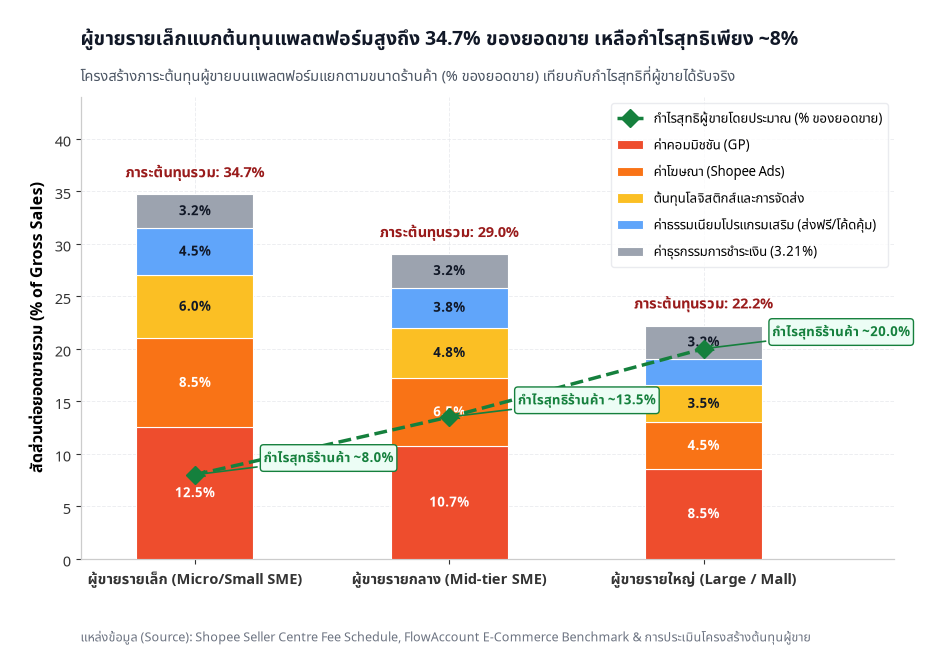

In [3]:
fig, ax = plt.subplots(figsize=(10.5, 6.0))

tiers = seller_df["seller_tier"].tolist()
x = np.arange(len(tiers))
width = 0.46

components = [
    ("commission_pct", "ค่าคอมมิชชัน (GP)", "#EE4D2D"),
    ("ads_pct", "ค่าโฆษณา (Shopee Ads)", "#F97316"),
    ("logistics_pct", "ต้นทุนโลจิสติกส์และการจัดส่ง", "#FBBF24"),
    ("promo_fee_pct", "ค่าธรรมเนียมโปรแกรมเสริม (ส่งฟรี/โค้ดคุ้ม)", "#60A5FA"),
    ("payment_fee_pct", "ค่าธุรกรรมการชำระเงิน (3.21%)", "#9CA3AF"),
]

bottom = np.zeros(len(tiers))
for col, label, color in components:
    vals = seller_df[col].values
    bars = ax.bar(x, vals, width, bottom=bottom, label=label, color=color, edgecolor="#FFFFFF", linewidth=0.8, zorder=3)
    for i, v in enumerate(vals):
        if v >= 3.0:
            ax.text(x[i], bottom[i] + v/2, f"{v:.1f}%", ha="center", va="center",
                    fontsize=9.5, fontweight="bold", color="#FFFFFF" if color in ["#EE4D2D", "#F97316"] else "#111827")
    bottom += vals

for i, tot in enumerate(seller_df["total_cost_pct"]):
    ax.text(x[i], tot + 1.0, f"ภาระต้นทุนรวม: {tot:.1f}%",
            ha="center", va="bottom", fontsize=10.5, fontweight="bold", color="#991B1B")

ax.plot(x, seller_df["seller_net_margin_pct"], color="#15803D", marker="D", markersize=9,
        linewidth=2.5, linestyle="--", label="กำไรสุทธิผู้ขายโดยประมาณ (% ของยอดขาย)", zorder=5)

for i, m in enumerate(seller_df["seller_net_margin_pct"]):
    ax.annotate(
        f"กำไรสุทธิร้านค้า ~{m:.1f}%",
        xy=(x[i], m), xytext=(x[i] + 0.27, m + 1.2),
        fontsize=9.5, fontweight="bold", color="#15803D",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="#ECFDF5", edgecolor="#15803D"),
        arrowprops=dict(arrowstyle="->", color="#15803D", lw=1.2),
        zorder=6
    )

ax.set_xticks(x)
ax.set_xticklabels(tiers, fontsize=10.5, fontweight="bold")
ax.set_ylabel("สัดส่วนต่อยอดขายรวม (% of Gross Sales)", fontweight="bold")
ax.set_ylim(0, 44)
ax.set_xlim(-0.45, 2.75)
ax.legend(loc="upper right", fontsize=9.5)

chart_style.add_title_and_source(
    ax,
    title="ผู้ขายรายเล็กแบกต้นทุนแพลตฟอร์มสูงถึง 34.7% ของยอดขาย เหลือกำไรสุทธิเพียง ~8%",
    subtitle="โครงสร้างภาระต้นทุนผู้ขายบนแพลตฟอร์มแยกตามขนาดร้านค้า (% ของยอดขาย) เทียบกับกำไรสุทธิที่ผู้ขายได้รับจริง",
    source_text="Shopee Seller Centre Fee Schedule, FlowAccount E-Commerce Benchmark & การประเมินโครงสร้างต้นทุนผู้ขาย"
)

plt.savefig("../charts/03_2_seller_cost_burden.png")
plt.show()

### กราฟ 3.3 — GP Reduction Impact (ก่อน/หลัง)
- **สื่ออะไร:** มาตรการของกระทรวงพาณิชย์กดดันให้ลดเพดาน GP สูงสุดจาก **19.26%** เหลือ **8.03% – 13.91%** (ลดลงสูงสุด -33.3%) ปิดทางไม่ให้ Shopee ขึ้นค่า GP กับร้านค้ารายย่อยเพื่อปั๊มกำไรระยะสั้น

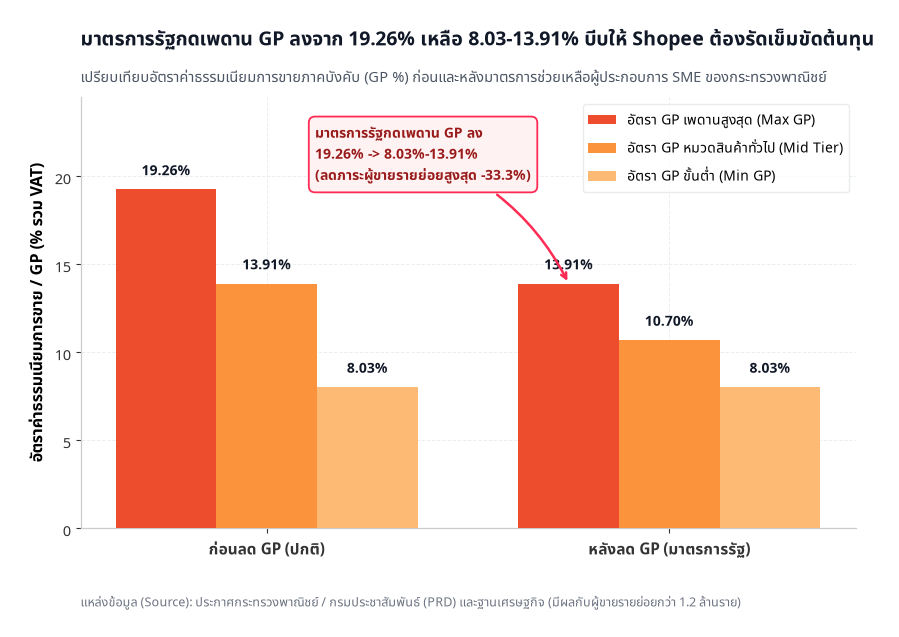

In [4]:
fig, ax = plt.subplots(figsize=(10.0, 5.6))

periods = gp_df["period"].tolist()
x = np.arange(len(periods))
width = 0.25

r_max = ax.bar(x - width, gp_df["max_gp_pct"], width, label="อัตรา GP เพดานสูงสุด (Max GP)", color=COLORS["Shopee"], zorder=3)
r_mid = ax.bar(x, gp_df["mid_gp_pct"], width, label="อัตรา GP หมวดสินค้าทั่วไป (Mid Tier)", color="#FB923C", zorder=3)
r_min = ax.bar(x + width, gp_df["min_gp_pct"], width, label="อัตรา GP ขั้นต่ำ (Min GP)", color="#FDBA74", zorder=3)

for bars in [r_max, r_mid, r_min]:
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.45, f"{h:.2f}%",
                ha="center", va="bottom", fontsize=10, fontweight="bold", color="#111827")

ax.annotate(
    "มาตรการรัฐกดเพดาน GP ลง\n19.26% -> 8.03%-13.91%\n(ลดภาระผู้ขายรายย่อยสูงสุด -33.3%)",
    xy=(1 - width, 13.91), xytext=(0.12, 19.8),
    fontsize=10, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#FEF2F2", edgecolor=COLORS["TikTok Red"], lw=1.3),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.2", color=COLORS["TikTok Red"], lw=1.8),
    zorder=5
)

ax.set_xticks(x)
ax.set_xticklabels(periods, fontsize=11, fontweight="bold")
ax.set_ylabel("อัตราค่าธรรมเนียมการขาย / GP (% รวม VAT)", fontweight="bold")
ax.set_ylim(0, 24.5)
ax.legend(loc="upper right")

chart_style.add_title_and_source(
    ax,
    title="มาตรการรัฐกดเพดาน GP ลงจาก 19.26% เหลือ 8.03-13.91% บีบให้ Shopee ต้องรัดเข็มขัดต้นทุน",
    subtitle="เปรียบเทียบอัตราค่าธรรมเนียมการขายภาคบังคับ (GP %) ก่อนและหลังมาตรการช่วยเหลือผู้ประกอบการ SME ของกระทรวงพาณิชย์",
    source_text="ประกาศกระทรวงพาณิชย์ / กรมประชาสัมพันธ์ (PRD) และฐานเศรษฐกิจ (มีผลกับผู้ขายรายย่อยกว่า 1.2 ล้านราย)"
)

plt.savefig("../charts/03_3_gp_reduction_impact.png")
plt.show()

> **Insight ของ Section 3:** *"Shopee มีกำไรแต่กำลังบางลง (-40.5% YoY) ขณะที่ผู้ขายรายย่อยก็แบกต้นทุนหนักและรัฐคุมเพดาน GP — ทรัพยากรมีจำกัด จึงไม่สามารถเผาเงินรบทุกสมรภูมิพร้อมกันได้"*